# 线偏振光通过 1/2 波片时的现象与 1/2 波片的作用

**原始数据**：以消光位置为初始状态（1/2 波片初始转角 0°、检偏器 0°），转动 1/2 波片转过 $\theta$ 后重新找到消光位置，记录检偏器转角 $\beta$。

**原理**：1/2 波片使 o 光与 e 光产生 $\pi$ 的相位差，入射的线偏振光出射后仍为线偏振光，但偏振面相对入射方向转过 $2\theta$（$\theta$ 为波片光轴相对初始位置的转角）。故消光时检偏器需相对初始位置转过

$$\beta = 2\theta$$

**验证方法**：作 $\beta$–$\theta$ 图并线性拟合，若斜率 $b\approx 2$、截距 $a\approx 0$，即说明偏振面转角是波片转角的两倍。

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.font_manager as fm

# ---------- 字体：英文用 Times New Roman，中文逐字回退到宋体 ----------
_installed = {f.name for f in fm.fontManager.ttflist}
_cjk_candidates = ['SimSun', 'STSong', 'Songti SC', 'Noto Serif SC',
                   'Source Han Serif SC', 'SimHei', 'Microsoft YaHei']
CJK_FONT = next((f for f in _cjk_candidates if f in _installed), 'DejaVu Sans')

# 注意：字体名必须直接写进 font.family 列表，matplotlib 才会逐字回退
rcParams['font.family']        = ['Times New Roman', CJK_FONT, 'DejaVu Sans']
rcParams['mathtext.fontset']   = 'stix'
rcParams['axes.unicode_minus'] = False
rcParams['figure.facecolor']   = 'white'
rcParams['savefig.facecolor']  = 'white'

pd.set_option('display.unicode.east_asian_width', True)

# ---------- 原始数据 ----------
theta_deg = np.arange(0, 100, 10, dtype=float)          # 1/2 波片转角 θ / (°)
beta_deg  = np.array([0.0, 21.5, 40.5, 60.9, 81.3,      # 检偏器转角 β / (°)
                     102.2, 120.8, 140.9, 160.2, 180.5])

df = pd.DataFrame({
    '1/2 波片转角 θ/(°)': theta_deg.astype(int),
    '检偏器转角 β/(°)':   beta_deg,
    'β/2':                beta_deg / 2,
    'β − 2θ':             beta_deg - 2 * theta_deg,
})
display(df.round(2))


def style_axes(ax, xlim, ylim, xticks, yticks, xlabel, ylabel):
    """统一坐标轴风格：四边框、刻度朝内、无网格（Origin 默认外观）。"""
    ax.set_xlim(*xlim)
    ax.set_ylim(*ylim)
    ax.set_xticks(xticks)
    ax.set_yticks(yticks)
    ax.tick_params(direction='in', length=4.5, width=0.9,
                   top=True, right=True, labelsize=11, pad=6)
    for sp in ax.spines.values():
        sp.set_linewidth(1.0)
    ax.set_xlabel(xlabel, fontsize=14, labelpad=6)
    ax.set_ylabel(ylabel, fontsize=14, labelpad=8)


def add_table_box(ax, rows, col_widths, bbox):
    """Origin 风格信息框：白色底、细灰边框、文字左对齐。"""
    tbl = ax.table(cellText=rows, cellLoc='left',
                   colWidths=col_widths, bbox=bbox)
    tbl.auto_set_font_size(False)
    for cell in tbl.get_celld().values():
        cell.set_edgecolor('#808080')
        cell.set_linewidth(0.6)
        cell.set_facecolor('white')
        cell.get_text().set_fontsize(9.5)
    return tbl

,1/2 波片转角 θ/(°),检偏器转角 β/(°),β/2,β − 2θ
0,0,0.0,0.00,0.0
1,10,21.5,10.75,1.5
2,20,40.5,20.25,0.5
3,30,60.9,30.45,0.9
4,40,81.3,40.65,1.3
5,50,102.2,51.10,2.2
6,60,120.8,60.40,0.8
7,70,140.9,70.45,0.9
8,80,160.2,80.10,0.2
9,90,180.5,90.25,0.5


拟合方程 : β = 0.9345 + 1.9988 · θ
斜率 b   = 1.9988 ± 0.0076
截距 a   = 0.9345 ± 0.4064
R² = 0.99988    Adj. R² = 0.99987


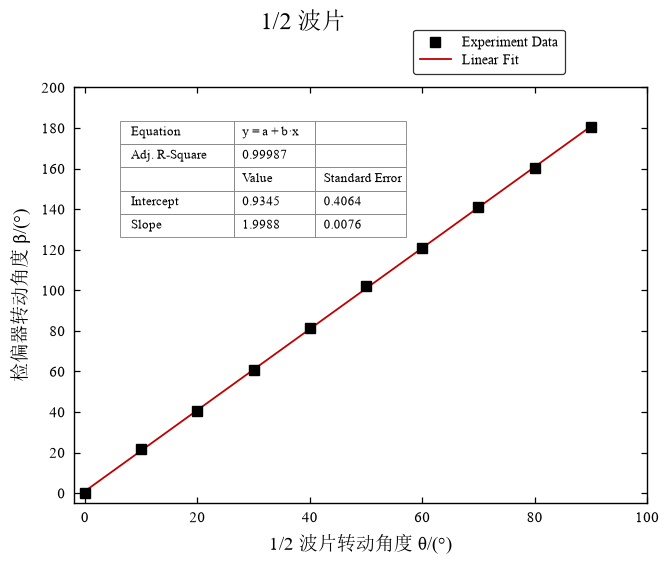

In [2]:
# ================= 图：散点 + 线性拟合（Origin 版式） =================
n      = len(theta_deg)
b, a   = np.polyfit(theta_deg, beta_deg, 1)    # 拟合 β = a + b·θ
y_hat  = a + b * theta_deg
ss_res = np.sum((beta_deg - y_hat) ** 2)
ss_tot = np.sum((beta_deg - beta_deg.mean()) ** 2)
r2     = 1 - ss_res / ss_tot
adj_r2 = 1 - (1 - r2) * (n - 1) / (n - 2)

sxx  = np.sum((theta_deg - theta_deg.mean()) ** 2)
s    = np.sqrt(ss_res / (n - 2))
se_b = s / np.sqrt(sxx)                                       # 斜率标准误差
se_a = s * np.sqrt(1 / n + theta_deg.mean() ** 2 / sxx)        # 截距标准误差

print(f'拟合方程 : β = {a:.4f} + {b:.4f} · θ')
print(f'斜率 b   = {b:.4f} ± {se_b:.4f}')
print(f'截距 a   = {a:.4f} ± {se_a:.4f}')
print(f'R² = {r2:.5f}    Adj. R² = {adj_r2:.5f}')

fig, ax = plt.subplots(figsize=(7.4, 5.4))

# 实验点（黑色实心方块）
# 图例文字用英文：中文标签在内联预览的图例里可能丢字（不影响存图），英文各处都正常
ax.plot(theta_deg, beta_deg, linestyle='none', marker='s', markersize=6.5,
        color='black', label='Experiment Data', zorder=3)

# 拟合直线
xx = np.linspace(0, 90, 200)
ax.plot(xx, a + b * xx, color='#C00000', linewidth=1.3,
        label='Linear Fit', zorder=2)

style_axes(ax, (-2, 100), (-5, 200),
           np.arange(0, 101, 20), np.arange(0, 201, 20),
           '1/2 波片转动角度 θ/(°)', '检偏器转动角度 β/(°)')

ax.set_title('1/2 波片', fontsize=17, x=0.40, pad=42)

leg = ax.legend(loc='lower left', bbox_to_anchor=(0.58, 1.015),
                fontsize=10, frameon=True, borderpad=0.5,
                labelspacing=0.35, handlelength=2.2)
leg.get_frame().set_linewidth(0.9)
leg.get_frame().set_edgecolor('black')

# ---- Origin 风格拟合结果框 ----
add_table_box(ax,
              rows=[['Equation',      'y = a + b·x',   ''],
                    ['Adj. R-Square', f'{adj_r2:.5f}', ''],
                    ['',              'Value',         'Standard Error'],
                    ['Intercept',     f'{a:.4f}',      f'{se_a:.4f}'],
                    ['Slope',         f'{b:.4f}',      f'{se_b:.4f}']],
              col_widths=[0.40, 0.28, 0.32],
              bbox=[0.08, 0.64, 0.50, 0.28])

plt.savefig('图1_半波片_线性拟合.png', dpi=300, bbox_inches='tight')
plt.show()

## 结果分析

- 拟合斜率 $b\approx 2$、截距 $a\approx 0$，$\mathrm{Adj.}\ R^2$ 接近 1，即 $\beta=2\theta$，
  说明 1/2 波片使线偏振光的偏振面相对入射方向转过两倍于波片转角的角，**波片确实起半波片作用**。
- 现象记录：1/2 波片每转过 360°，检测到 4 次消光；检偏器每转过 360°，检测到 2 次消光。
  这是因为波片转过 180° 偏振面转 360°，而检偏器需转 180° 才回到同一消光取向。
- 各点 $\beta-2\theta$ 的偏差在 2° 以内，主要来自消光位置判断（人眼判读最小的目测误差）与角度读数误差。